In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Yoseva Faurensia Sitohang_202431195

In [2]:
#baca dataset hasil scraping
df = pd.read_csv("pokemon_dataset.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

# Yoseva Faurensia Sitohang_202431195

Ukuran dataset: (1261, 10)


,nomor,nama,tipe,total,hp,attack,defense,sp_attack,sp_defense,speed
0,1,Bulbasaur,Grass Poison,318,45,49,49,65,65,45
1,2,Ivysaur,Grass Poison,405,60,62,63,80,80,60
2,3,Venusaur,Grass Poison,525,80,82,83,100,100,80
3,3,VenusaurMega Venusaur,Grass Poison,625,80,100,123,122,120,80
4,4,Charmander,Fire,309,39,52,43,60,50,65


In [3]:
fitur = ["hp", "attack", "defense", "sp_attack", "sp_defense", "speed"]
target = "total"

df = df.dropna(subset=fitur + [target])

print("Jumlah data setelah menghapus data kosong:", len(df))

# Yoseva Faurensia Sitohang_202431195

Jumlah data setelah menghapus data kosong: 1261


In [4]:
X = df[fitur]
y = df[target]

print("Fitur X:")
display(X.head())

print("Target y:")
display(y.head())

# Yoseva Faurensia Sitohang_202431195

Fitur X:


,hp,attack,defense,sp_attack,sp_defense,speed
0,45,49,49,65,65,45
1,60,62,63,80,80,60
2,80,82,83,100,100,80
3,80,100,123,122,120,80
4,39,52,43,60,50,65


Target y:


0    318
1    405
2    525
3    625
4    309
Name: total, dtype: int64

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

# Yoseva Faurensia Sitohang_202431195

Jumlah data latih: 1008
Jumlah data uji: 253


In [6]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model berhasil dilatih.")

# Yoseva Faurensia Sitohang_202431195

Model berhasil dilatih.


In [7]:
y_pred = model.predict(X_test)

hasil = pd.DataFrame({
    "Nilai Aktual": y_test,
    "Nilai Prediksi": y_pred
})

display(hasil.head(10))

# Yoseva Faurensia Sitohang_202431195

,Nilai Aktual,Nilai Prediksi
5,405,405.0
432,355,355.0
52,299,299.0
989,680,680.0
186,525,525.0
18,395,395.0
317,580,580.0
762,515,515.0
546,479,479.0
1009,700,700.0


In [8]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Koefisien:", model.coef_)
print("Intercept:", model.intercept_)
print("MSE:", mse)
print("R2 Score:", r2)

# Yoseva Faurensia Sitohang_202431195

Koefisien: [1. 1. 1. 1. 1. 1.]
Intercept: -2.2737367544323206e-13
MSE: 8.215228647244551e-27
R2 Score: 1.0


In [9]:
persamaan = f"Total = {model.intercept_:.2f}"

for nama_fitur, koef in zip(fitur, model.coef_):
    persamaan += f" + ({koef:.2f} * {nama_fitur})"

print("Persamaan Regresi Linear:")
print(persamaan)

# Yoseva Faurensia Sitohang_202431195

Persamaan Regresi Linear:
Total = -0.00 + (1.00 * hp) + (1.00 * attack) + (1.00 * defense) + (1.00 * sp_attack) + (1.00 * sp_defense) + (1.00 * speed)


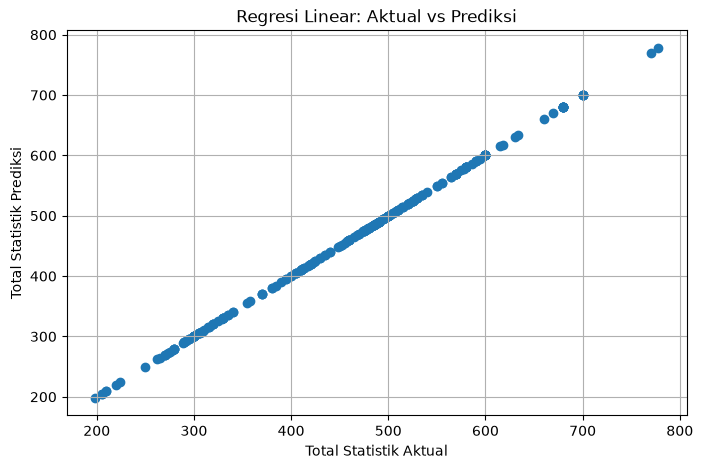

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)

plt.xlabel("Total Statistik Aktual")
plt.ylabel("Total Statistik Prediksi")
plt.title("Regresi Linear: Aktual vs Prediksi")
plt.grid(True)
plt.show()

# Yoseva Faurensia Sitohang_202431195